# ML Lab 06 (Lab Task 3: Imbalanced Classification)

**Dataset:** Synthetic imbalanced binary dataset (fraud-detection style, about 5% positive class)
**Model:** Logistic Regression, before and after `class_weight="balanced"`

Steps covered:
13. Create or select an imbalanced binary classification dataset
14. Train a baseline classifier
15. Report accuracy, precision, recall and F1-score
16. Explain why accuracy alone can be misleading
17. Try `class_weight="balanced"` where supported
18. Compare the metrics before and after the change

## Setup: Imports

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, ConfusionMatrixDisplay)

## Step 13: Create an Imbalanced Binary Classification Dataset
We generate 10,000 samples where only about 5% belong to the positive class. Think of it as transactions where 1 = fraud and 0 = legitimate. Fraud is rare, but missing it is costly.

In [ ]:
X, y = make_classification(
    n_samples=10000,
    n_features=20,
    n_informative=10,
    n_redundant=2,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],     # 95% negative, 5% positive
    class_sep=1.0,
    flip_y=0.01,
    random_state=42,
)

counts = pd.Series(y).value_counts().sort_index()
print("Class counts:")
print(counts.rename({0: "0 (majority / legitimate)", 1: "1 (minority / fraud)"}))
print()
print("Class percentages:")
print((pd.Series(y).value_counts(normalize=True).sort_index() * 100).round(2))
print()
print("Imbalance ratio (majority : minority) = %.1f : 1" % (counts[0] / counts[1]))

Class counts:
0 (majority / legitimate)    9449
1 (minority / fraud)          551
Name: count, dtype: int64

Class percentages:
0    94.49
1     5.51
Name: proportion, dtype: float64

Imbalance ratio (majority : minority) = 17.1 : 1


In [ ]:
# Stratified split so that train and test keep the same 95/5 class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Train:", X_train.shape, "| positives:", int(y_train.sum()), f"({y_train.mean():.2%})")
print("Test :", X_test.shape,  "| positives:", int(y_test.sum()),  f"({y_test.mean():.2%})")

Train: (8000, 20) | positives: 441 (5.51%)
Test : (2000, 20) | positives: 110 (5.50%)


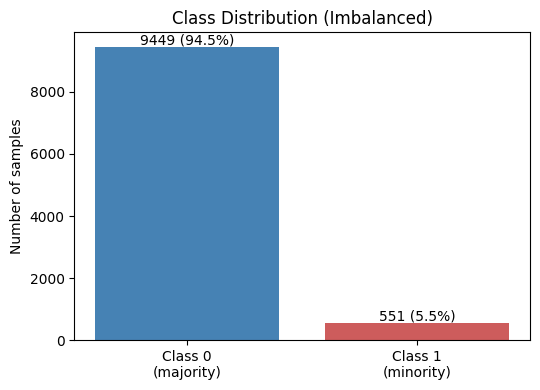

In [ ]:
# Plot: class distribution
fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(["Class 0\n(majority)", "Class 1\n(minority)"], counts.values,
              color=["steelblue", "indianred"])
ax.set_ylabel("Number of samples")
ax.set_title("Class Distribution (Imbalanced)")
for b, pct in zip(bars, counts.values / counts.sum() * 100):
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 80,
            f"{int(b.get_height())} ({pct:.1f}%)", ha="center")
plt.tight_layout()
plt.show()

## Step 14: Train a Baseline Classifier
The baseline is a plain Logistic Regression with no special handling of the imbalance. For reference, we also train a "dummy" model that always predicts the majority class.

In [ ]:
# Baseline model: standard Logistic Regression (no class weights)
baseline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)
print("Baseline Logistic Regression trained.")

Baseline Logistic Regression trained.


In [ ]:
# Reference: a model that ignores the features and always predicts the majority class
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
print("Dummy classifier (always predicts class 0) trained.")
print("Unique predictions:", np.unique(y_pred_dummy))

Dummy classifier (always predicts class 0) trained.
Unique predictions: [0]


## Step 15: Report Accuracy, Precision, Recall and F1-Score

In [ ]:
def report(y_true, y_pred):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1-Score":  f1_score(y_true, y_pred, zero_division=0),
    }

base_metrics  = report(y_test, y_pred_base)
dummy_metrics = report(y_test, y_pred_dummy)

print("=== Baseline Logistic Regression ===")
for k, v in base_metrics.items():
    print(f"{k:10s}: {v:.4f}")

print()
print("=== Dummy (always predicts 0) ===")
for k, v in dummy_metrics.items():
    print(f"{k:10s}: {v:.4f}")

=== Baseline Logistic Regression ===
Accuracy  : 0.9755
Precision : 0.9692
Recall    : 0.5727
F1-Score  : 0.7200

=== Dummy (always predicts 0) ===
Accuracy  : 0.9450
Precision : 0.0000
Recall    : 0.0000
F1-Score  : 0.0000


In [ ]:
# Baseline confusion matrix
cm_base = confusion_matrix(y_test, y_pred_base)
tn, fp, fn, tp = cm_base.ravel()
print(pd.DataFrame(cm_base,
      index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))
print()
print(f"TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}")
print(f"Out of {tp + fn} real positive cases, the baseline missed {fn}.")

          Predicted 0  Predicted 1
Actual 0         1888            2
Actual 1           47           63

TN = 1888, FP = 2, FN = 47, TP = 63
Out of 110 real positive cases, the baseline missed 47.


## Step 16: Why Accuracy Alone Can Be Misleading
With 95% of samples in one class, a model can score high accuracy while being useless for the class we care about. The comparison below makes this visible.

In [ ]:
misleading = pd.DataFrame({
    "Dummy (always 0)": dummy_metrics,
    "Baseline Logistic Regression": base_metrics,
}).round(4)
print(misleading)
print()
print(f"The dummy model never detects a single positive case (recall = {dummy_metrics['Recall']:.2f}),")
print(f"yet its accuracy is {dummy_metrics['Accuracy']:.2%}.")

           Dummy (always 0)  Baseline Logistic Regression
Accuracy              0.945                        0.9755
Precision             0.000                        0.9692
Recall                0.000                        0.5727
F1-Score              0.000                        0.7200

The dummy model never detects a single positive case (recall = 0.00),
yet its accuracy is 94.50%.


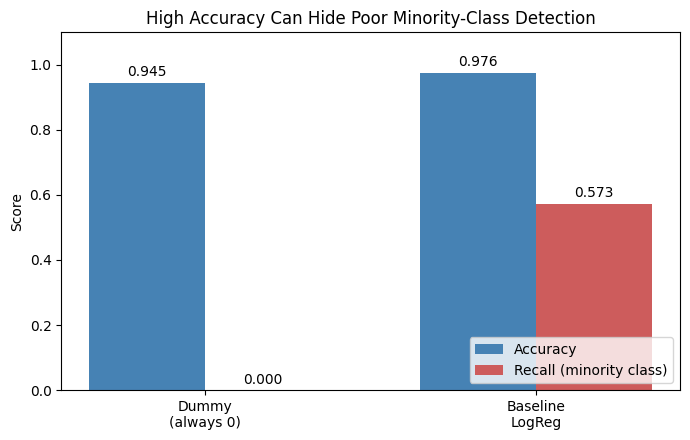

In [ ]:
# Plot: accuracy vs recall for the dummy model and the baseline
labels = ["Dummy\n(always 0)", "Baseline\nLogReg"]
acc = [dummy_metrics["Accuracy"], base_metrics["Accuracy"]]
rec = [dummy_metrics["Recall"],   base_metrics["Recall"]]

x = np.arange(2)
w = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar(x - w/2, acc, w, label="Accuracy", color="steelblue")
b2 = ax.bar(x + w/2, rec, w, label="Recall (minority class)", color="indianred")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Score")
ax.set_title("High Accuracy Can Hide Poor Minority-Class Detection")
ax.legend(loc="lower right")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.02,
                f"{b.get_height():.3f}", ha="center")
plt.tight_layout()
plt.show()

**Explanation**

- **Accuracy counts every prediction equally.** When 95% of the samples are negative, predicting "negative" for everyone is already about 95% accurate, even though the model finds none of the positive cases.
- **The rare class is the one that matters.** In fraud detection, disease screening or fault detection, the minority class is the reason the model exists. Accuracy is dominated by the majority class and hides failures on the minority class.
- **Better metrics for imbalanced data:**
  - **Recall** shows how many real positives were found.
  - **Precision** shows how many predicted positives were correct.
  - **F1-Score** balances the two.
  - The confusion matrix shows exactly where the errors are.
- **Rule of thumb:** on imbalanced data, always report recall, precision and F1 along with accuracy, and compare against a majority-class baseline.

## Step 17: Try `class_weight="balanced"`
With `class_weight="balanced"`, scikit-learn weights each class inversely to its frequency, so errors on the rare class count much more during training:

weight(class c) = n_samples / (n_classes × n_samples_in_class_c)

In [ ]:
# Show the weights that 'balanced' assigns, calculated from the training labels
n_samples = len(y_train)
n_classes = 2
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())

w_neg = n_samples / (n_classes * n_neg)
w_pos = n_samples / (n_classes * n_pos)
print(f"Weight for class 0: {w_neg:.3f}")
print(f"Weight for class 1: {w_pos:.3f}")
print(f"A mistake on a positive sample counts about {w_pos / w_neg:.1f}x more than on a negative sample.")

Weight for class 0: 0.529
Weight for class 1: 9.070
A mistake on a positive sample counts about 17.1x more than on a negative sample.


In [ ]:
# Same model as the baseline, with only one change: class_weight="balanced"
balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])
balanced.fit(X_train, y_train)
y_pred_bal = balanced.predict(X_test)

bal_metrics = report(y_test, y_pred_bal)
print("=== Logistic Regression with class_weight='balanced' ===")
for k, v in bal_metrics.items():
    print(f"{k:10s}: {v:.4f}")

=== Logistic Regression with class_weight='balanced' ===
Accuracy  : 0.8900
Precision : 0.3203
Recall    : 0.8909
F1-Score  : 0.4712


In [ ]:
cm_bal = confusion_matrix(y_test, y_pred_bal)
tn_b, fp_b, fn_b, tp_b = cm_bal.ravel()
print(pd.DataFrame(cm_bal,
      index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))
print()
print(f"TN = {tn_b}, FP = {fp_b}, FN = {fn_b}, TP = {tp_b}")
print(f"Out of {tp_b + fn_b} real positive cases, the balanced model missed {fn_b}.")

          Predicted 0  Predicted 1
Actual 0         1682          208
Actual 1           12           98

TN = 1682, FP = 208, FN = 12, TP = 98
Out of 110 real positive cases, the balanced model missed 12.


## Step 18: Compare Metrics Before and After

In [ ]:
compare = pd.DataFrame({
    "Before (baseline)": base_metrics,
    "After (balanced)":  bal_metrics,
})
compare["Change"] = compare["After (balanced)"] - compare["Before (baseline)"]
print(compare.round(4))
print()

for metric, change in compare["Change"].items():
    direction = "increased" if change > 0 else "decreased" if change < 0 else "did not change"
    print(f"{metric:10s} {direction} by {abs(change):.4f}")

           Before (baseline)  After (balanced)  Change
Accuracy              0.9755            0.8900 -0.0855
Precision             0.9692            0.3203 -0.6490
Recall                0.5727            0.8909  0.3182
F1-Score              0.7200            0.4712 -0.2488



Accuracy   decreased by 0.0855
Precision  decreased by 0.6490
Recall     increased by 0.3182
F1-Score   decreased by 0.2488


In [ ]:
# Compare the error counts before and after
errors = pd.DataFrame({
    "Before (baseline)": {"TP (fraud caught)": tp, "FN (fraud missed)": fn,
                          "FP (false alarms)": fp, "TN": tn},
    "After (balanced)":  {"TP (fraud caught)": tp_b, "FN (fraud missed)": fn_b,
                          "FP (false alarms)": fp_b, "TN": tn_b},
})
print(errors)

                   Before (baseline)  After (balanced)
TP (fraud caught)                 63                98
FN (fraud missed)                 47                12
FP (false alarms)                  2               208
TN                              1888              1682


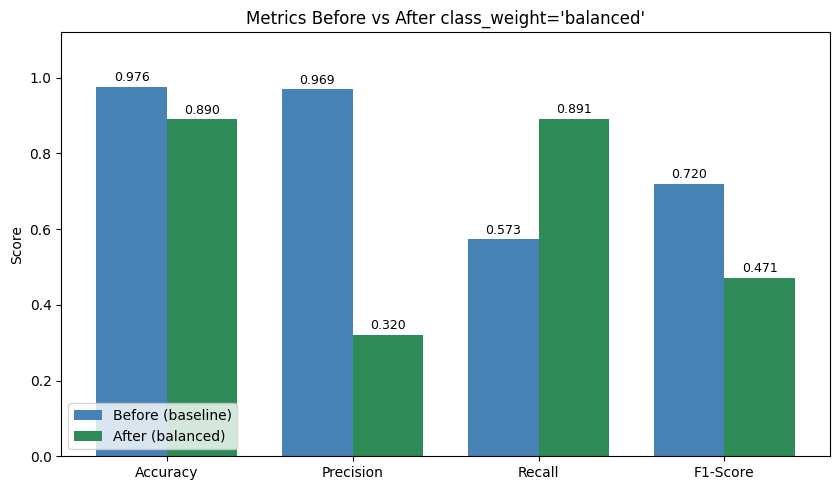

In [ ]:
# Plot: grouped bar chart of the metrics before and after
metrics = list(base_metrics.keys())
x = np.arange(len(metrics))
w = 0.38

fig, ax = plt.subplots(figsize=(8.5, 5))
b1 = ax.bar(x - w/2, [base_metrics[m] for m in metrics], w, label="Before (baseline)", color="steelblue")
b2 = ax.bar(x + w/2, [bal_metrics[m]  for m in metrics], w, label="After (balanced)",  color="seagreen")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Metrics Before vs After class_weight='balanced'")
ax.legend(loc="lower left")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015,
                f"{b.get_height():.3f}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

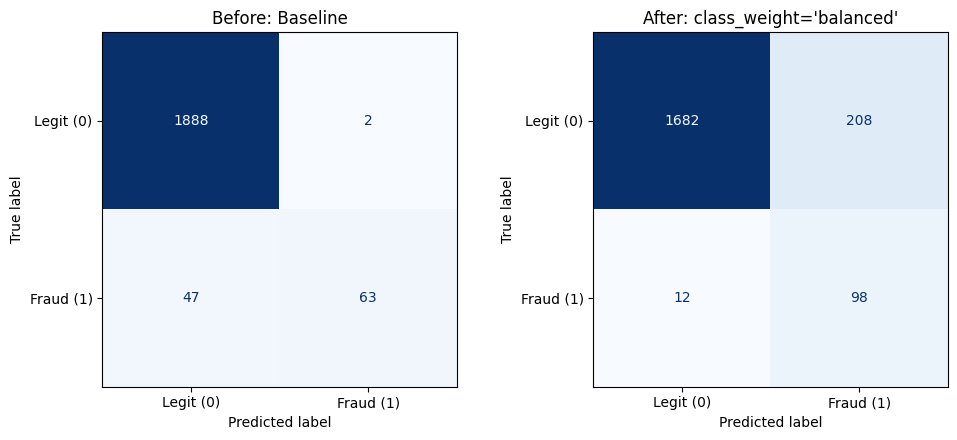

In [ ]:
# Plot: confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, cm, title in zip(axes, [cm_base, cm_bal],
                         ["Before: Baseline", "After: class_weight='balanced'"]):
    ConfusionMatrixDisplay(cm, display_labels=["Legit (0)", "Fraud (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title)
plt.tight_layout()
plt.show()

### Interpretation of the Comparison

- **Recall increases.** Because mistakes on the rare class now cost more, the model flags many more of the real positive cases. Fewer frauds are missed (FN drops).
- **Precision decreases.** To catch more positives, the model also raises more false alarms (FP grows), so a smaller share of its positive predictions are correct.
- **Accuracy decreases.** The model gives up some of the easy majority-class correctness. This is a good example of why a lower accuracy does not mean a worse model on imbalanced data.
- **F1-Score depends on the balance.** F1 can go up or down depending on how much precision is lost to gain recall. Read the printed "Change" column above for the exact movement in this run.

**Which model is better?** It depends on the cost of each error:
- If missing a positive case is very costly (fraud, cancer screening), the balanced model is preferred because it catches more positives, and the extra false alarms can be reviewed later.
- If false alarms are very costly (for example blocking legitimate customers), the baseline or a threshold-tuned model may be preferred.

`class_weight="balanced"` is therefore a trade-off tool, not a free improvement. Other options include threshold tuning, resampling (SMOTE, undersampling, applied only inside the training folds), and using PR-AUC as the evaluation metric.

## Conclusion
1. The dataset has a 95 : 5 class split, which makes accuracy a poor primary metric.
2. A model that never predicts the positive class still achieves about 95% accuracy with 0 recall, so accuracy alone is misleading.
3. Adding `class_weight="balanced"` makes the model pay more attention to the minority class: recall rises substantially, while precision and accuracy fall.
4. The best choice depends on whether false negatives or false positives are more expensive in the real application. Always report precision, recall and F1 along with accuracy for imbalanced problems.